In [1]:
import sys

print(sys.executable)

print(sys.version)

c:\Users\Vedant\AppData\Local\Programs\Python\Python313\python.exe
3.13.16 (tags/v3.13.16:cbc944f, Sep 30 2026, 19:17:50) [MSC v.1944 64 bit (AMD64)]


In [2]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [4]:
df = pd.read_csv('Churn_Modelling.csv')

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


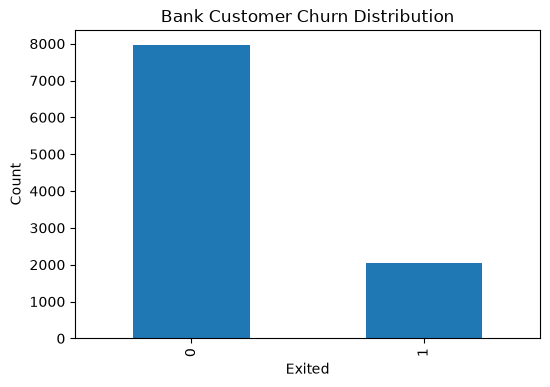

In [6]:
plt.figure(figsize=(6, 4))

plt.xlabel('Exited')

plt.ylabel('Count')

df['Exited'].value_counts().plot.bar()

plt.title('Bank Customer Churn Distribution')

plt.show()

In [7]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [8]:
df = pd.concat(
    [
        df,
        pd.get_dummies(df['Geography'], prefix='Geo', dtype=int)
    ],
    axis=1
)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
 14  Geo_France       10000 non-null  int64  
 15  Geo_Germany      10000 non-null  int64  
 16  Geo_Spain        10000 non-null  int64  
dtypes: float64(2), int64(12)

In [10]:
df.drop(
    columns=[
        'RowNumber',
        'CustomerId',
        'Surname',
        'Geography',
        'Gender'
    ],
    inplace=True
)

df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geo_France,Geo_Germany,Geo_Spain
0,619,42,2,0.00,1,1,1,101348.88,1,1,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,0,1
2,502,42,8,159660.80,3,1,0,113931.57,1,1,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,1,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,0,1


In [11]:
y = df['Exited'].values

X = df.drop(columns=['Exited']).values

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (10000, 11)
Target Shape: (10000,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=20,
    test_size=0.25,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (7500, 11)
Testing Data: (2500, 11)


In [13]:
from sklearn.preprocessing import StandardScaler

std_x = StandardScaler()

X_train = std_x.fit_transform(X_train)

X_test = std_x.transform(X_test)

In [14]:
print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

Training Data Shape: (7500, 11)
Testing Data Shape: (2500, 11)


In [15]:
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.models import Sequential

In [16]:
model = Sequential()

model.add(Input(shape=(X_train.shape[1],)))

model.add(Dense(100, activation='relu'))

model.add(Dropout(0.2))

model.add(Dense(50, activation='relu'))

model.add(Dense(1, activation='sigmoid'))

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,301 (24.61 KB)

 Trainable params: 6,301 (24.61 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer='adam',
    metrics=['accuracy'],
    loss='binary_crossentropy'
)

In [19]:
history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    validation_split=0.1,
    epochs=100,
    verbose=1
)

Epoch 1/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7850 - loss: 0.4819 - val_accuracy: 0.8333 - val_loss: 0.4083
Epoch 2/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8221 - loss: 0.4189 - val_accuracy: 0.8453 - val_loss: 0.3837
Epoch 3/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8424 - loss: 0.3935 - val_accuracy: 0.8600 - val_loss: 0.3589
Epoch 4/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8481 - loss: 0.3719 - val_accuracy: 0.8680 - val_loss: 0.3486
Epoch 5/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8516 - loss: 0.3623 - val_accuracy: 0.8680 - val_loss: 0.3399
Epoch 6/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8490 - loss: 0.3590 - val_accuracy: 0.8680 - val_loss: 0.3410
Epoch 7/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8526 - loss: 0.3582 - val_accuracy: 0.8587 - val_loss: 0.3394
Epoch 8/100
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8551 - loss: 0.3528 - val_accu

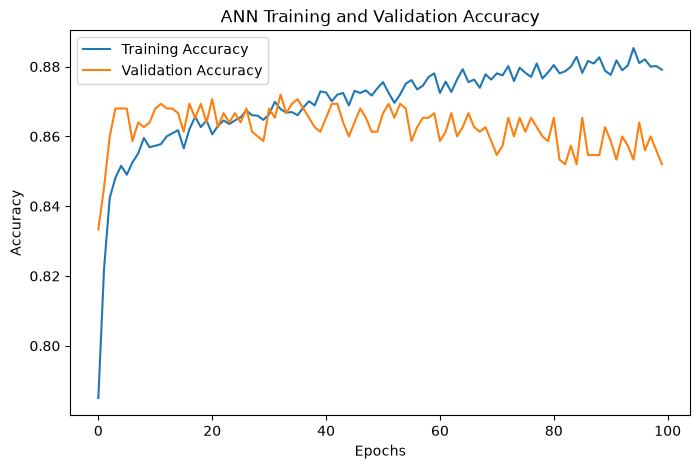

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.title('ANN Training and Validation Accuracy')

plt.legend()

plt.show()

In [21]:
pred = model.predict(X_test)

y_pred = (pred > 0.5).astype(int).ravel()

print("First 10 Predictions:")

print(y_pred[:10])

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [22]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [23]:
accuracy = accuracy_score(y_test, y_pred)

print("ANN Model Accuracy:", accuracy)

print("Accuracy Percentage:", accuracy * 100, "%")

ANN Model Accuracy: 0.8612
Accuracy Percentage: 86.11999999999999 %


Confusion Matrix:
[[1914   77]
 [ 270  239]]


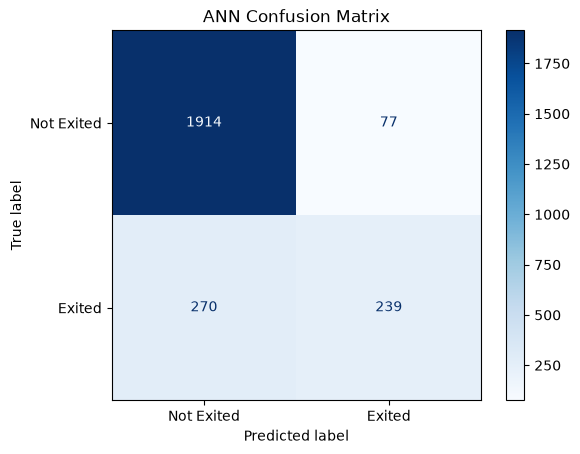

In [24]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")

print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Exited', 'Exited']
)

display.plot(cmap='Blues')

plt.title('ANN Confusion Matrix')

plt.show()

In [25]:
print("ANN Classification Report:")

print(classification_report(y_test, y_pred))

ANN Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1991
           1       0.76      0.47      0.58       509

    accuracy                           0.86      2500
   macro avg       0.82      0.72      0.75      2500
weighted avg       0.85      0.86      0.85      2500



In [26]:
from sklearn.neural_network import MLPClassifier

nn_classifier = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='logistic',
    solver='adam',
    max_iter=500,
    random_state=20,
    early_stopping=True
)

nn_classifier.fit(X_train, y_train)

,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'logistic'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",20
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating

In [27]:
y_pred2 = nn_classifier.predict(X_test)

print("First 10 Predictions:")

print(y_pred2[:10])

First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [28]:
accuracy2 = accuracy_score(y_test, y_pred2)

print("MLPClassifier Accuracy:", accuracy2)

print("Accuracy Percentage:", accuracy2 * 100, "%")

MLPClassifier Accuracy: 0.812
Accuracy Percentage: 81.2 %


MLPClassifier Confusion Matrix:
[[1968   23]
 [ 447   62]]


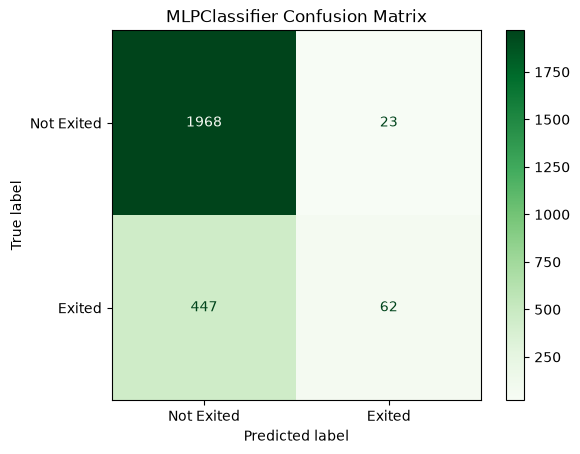

In [29]:
cm2 = confusion_matrix(y_test, y_pred2)

print("MLPClassifier Confusion Matrix:")

print(cm2)

display2 = ConfusionMatrixDisplay(
    confusion_matrix=cm2,
    display_labels=['Not Exited', 'Exited']
)

display2.plot(cmap='Greens')

plt.title('MLPClassifier Confusion Matrix')

plt.show()

In [30]:
comparison = pd.DataFrame({
    'Model': ['TensorFlow ANN', 'MLPClassifier'],
    'Accuracy': [accuracy, accuracy2]
})

print(comparison)

            Model  Accuracy
0  TensorFlow ANN    0.8612
1   MLPClassifier    0.8120


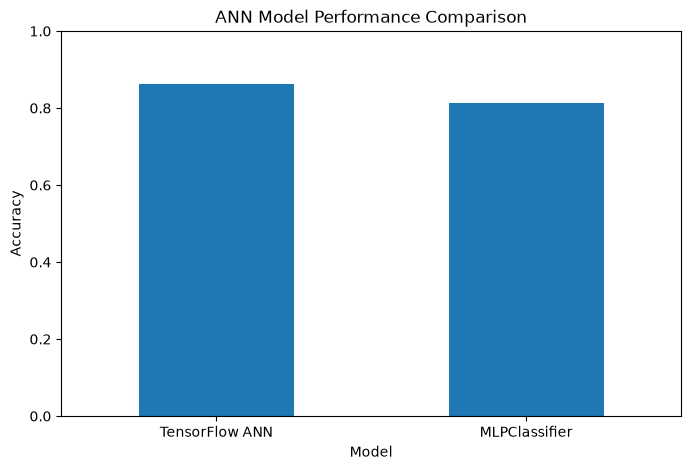

In [31]:
comparison.set_index('Model').plot(
    kind='bar',
    figsize=(8, 5),
    legend=False
)

plt.title('ANN Model Performance Comparison')

plt.ylabel('Accuracy')

plt.xlabel('Model')

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.show()